# Scattering Overview

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/05-scattering/01-scattering_overview.ipynb)

The {py:mod}`scattering <udkm1Dsim.simulations.scattering>` package calculates the reflection and transmission of optical light and X-rays of a sample structure, also for inhomogeneous strain and magnetization profiles as given by other simulations.
Its formalisms belong to two families:

* The **atomistic formalisms** scatter from the atoms of crystalline unit cells with their atomic form factors $f(q_z, E)$ resulting in characteristic Bragg reflections for the X-ray diffraction, see the [X-ray diffraction examples](#example_kinematical_xray).
* The **multilayer formalisms** treat every layer as a homogeneous medium with its dielectric tensor $\varepsilon_{ij}(E)$, see the [example of the dielectric tensor](#example_dielectric), from the optical to the hard X-ray range.
  They differ only in the eigenmodes of the layers and in the assembly of the layer stack from the sample structure.

:::{admonition} References {cite}`parratt1954,nevot1980,berreman1972,ko1988,stepanov2000,elzo2012,bay2022,warren1990,alsnielsen2011`
:class: seealso
- L. G. Parratt, *Surface Studies of Solids by Total Reflection of X-Rays*, [Phys. Rev. 95, 359 (1954)](https://doi.org/10.1103/PhysRev.95.359)
- L. Névot and P. Croce, *Caractérisation des surfaces par réflexion rasante de rayons X*, [Rev. Phys. Appl. 15, 761 (1980)](https://doi.org/10.1051/rphysap:01980001503076100)
- D. W. Berreman, *Optics in Stratified and Anisotropic Media: 4x4-Matrix Formulation*, [J. Opt. Soc. Am. 62, 502 (1972)](https://doi.org/10.1364/JOSA.62.000502)
- D. Y. K. Ko and J. R. Sambles, *Scattering matrix method for propagation of radiation in stratified media*, [J. Opt. Soc. Am. A 5, 1863 (1988)](https://doi.org/10.1364/JOSAA.5.001863)
- S. A. Stepanov and S. K. Sinha, *X-ray resonant reflection from magnetic multilayers: Recursion matrix algorithm*, [Phys. Rev. B 61, 15302 (2000)](https://doi.org/10.1103/PhysRevB.61.15302)
- M. Elzo, et al., *X-ray resonant magnetic reflectivity of stratified magnetic structures: Eigenwave formalism and application to a W/Fe/W trilayer*, [J. Magn. Magn. Mater. 324, 105 (2012)](https://doi.org/10.1016/j.jmmm.2011.07.019)
- M. M. Bay, S. Vignolini, and K. Vynck, *PyLlama: A stable and versatile Python toolkit for the electromagnetic modelling of multilayered anisotropic media*, [Comput. Phys. Commun. 273, 108256 (2022)](https://doi.org/10.1016/j.cpc.2021.108256)
- B. E. Warren, *X-Ray Diffraction* (Dover Publications, New York, 1990)
- J. Als-Nielsen and D. McMorrow, *Elements of Modern X-ray Physics* (Wiley, 2011), [doi:10.1002/9781119998365](https://doi.org/10.1002/9781119998365)
:::


The **atomistic formalisms** neglect the magnetization and anisotropy:

| formalism | scattering | assembly | typical use |
|---|---|---|---|
| {py:class}`XrayKin <udkm1Dsim.simulations.scattering.kinematical.XrayKin>` | kinematical, single scattering | sum of the unit cells | weak Bragg reflections, thin films |
| {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>` | dynamical, $\sigma$ and $\pi$ | transfer matrices of the atomic layers | strong Bragg reflections, thick crystals |

`XrayKin` follows the kinematical theory of {cite:t}`warren1990` and `XrayDyn` the dynamical theory of {cite:t}`alsnielsen2011`, which multiplies the $2 \times 2$ transfer matrices of the atomic layers for $\sigma$ and $\pi$.

For the **multilayer formalisms**, their eigenmodes determine whether they include an arbitrary magnetization (magnetic) and an anisotropic non-magnetic dielectric tensor $\varepsilon^0$ (anisotropic):

| formalism | eigenmodes | assembly | magnetic | anisotropic | typical use |
|---|---|---|:-:|:-:|---|
| {py:class}`Parratt <udkm1Dsim.simulations.scattering.parratt.Parratt>` | scalar $\sigma$, $\pi$ | recursion | – | – | fast non-magnetic reflectivity, also for many delays |
| {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` | 1st order in $\varepsilon^m$ | transfer matrices | ✓ | – | fast magnetic reflectivity |
| {py:class}`Stepanov <udkm1Dsim.simulations.scattering.stepanov.Stepanov>` | 1st order in $\varepsilon^m$ | scattering matrices | ✓ | – | thick, absorbing, or repeated magnetic stacks |
| {py:class}`BerremanElzo <udkm1Dsim.simulations.scattering.berreman.BerremanElzo>` | exact | transfer matrices | ✓ | ✓ | anisotropic and strongly magnetic layers |
| {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>` | exact | scattering matrices | ✓ | ✓ | reference for all multilayer formalisms |

`Parratt` follows the recursion of {cite:t}`parratt1954` with the roughness of {cite:t}`nevot1980`, and `Elzo` the eigenwave formalism of {cite:t}`elzo2012` with the transfer matrices of {cite:t}`berreman1972`.
`Stepanov` assembles the same eigenmodes by the scattering matrices of {cite:t}`ko1988` with the recursion of {cite:t}`stepanov2000` for magnetic X-ray multilayers.
`BerremanElzo` and `BerremanStepanov` use the exact eigenmodes of the matrix of {cite:t}`berreman1972` for an arbitrary dielectric tensor, as e.g. also PyLlama {cite:p}`bay2022`.
They are ported from or based on the implementations of [Dyna](https://gitlab.com/dynadevgroup/Dyna).

All formalisms share the photon energies, angles, and polarizations, which are introduced first, and the multilayer formalisms also share their high-level methods.
Finally, the multilayer formalisms are compared for the W/Fe/W trilayer of {cite:t}`elzo2012`.

## Transfer and Scattering Matrices

<img src="./multilayer_sketch.svg" alt="Sketch of the multilayer stack in the frame of the sample" class="align-center gallery_thumbnail" width="80%">

In the frame of the sample, $z$ is the surface normal pointing out of the sample towards the superstrate, $yz$ is the plane of incidence, and $x$ is along the $\sigma$ polarization, see the sketch.
The light is incident from the superstrate at the grazing angle $\vartheta$ with the electric field $\mathbf{E}^\mathrm{in} = (E_\sigma, E_\pi)$, which is reflected and transmitted by the Jones matrices $R$ and $T$,

$$\mathbf{E}^\mathrm{r} = R\, \mathbf{E}^\mathrm{in}, \quad \mathbf{E}^\mathrm{t} = T\, \mathbf{E}^\mathrm{in}.$$

In every layer $j$, the light propagates in two eigenmodes down into the sample and two up, one for each of the two independent polarizations, e.g. $\sigma$ and $\pi$ in an isotropic layer, which are mixed by an anisotropy or magnetization.
The in-plane electric and magnetic fields of the four modes form the boundary matrix $A_j$ and their normal wave vectors give their propagation $P_j$ through the thickness of the layer.
The multilayer formalisms differ in these eigenmodes and in the assembly of the stack from them by transfer or scattering matrices.

The transfer matrices of `Elzo` and `BerremanElzo`, as introduced by {cite:t}`berreman1972`, relate the fields at the top of the stack to the ones at its bottom,

$$\begin{pmatrix} \mathbf{E}^\mathrm{t} \\ \mathbf{0} \end{pmatrix} = M \begin{pmatrix} \mathbf{E}^\mathrm{in} \\ \mathbf{E}^\mathrm{r} \end{pmatrix}, \quad M = \prod_j P_j A_j^{-1} A_{j-1},$$

where $A_j^{-1} A_{j-1}$ projects the modes of the layer above onto the ones of layer $j$ at their interface.
The Jones matrices follow from the $2 \times 2$ blocks of $M$ for the down- and up-going modes, which are labeled by $t$ and $r$,

$$R = -M_{rr}^{-1} M_{rt}, \quad T = M_{tt} - M_{tr} M_{rr}^{-1} M_{rt}.$$

Internally, they are calculated for the eigenmodes of the superstrate and substrate and then converted to the electric fields in the linear $(\sigma, \pi)$ basis.

However, the up-going modes grow exponentially through every layer, so that the transfer matrices lose their numerical precision for thick or strongly absorbing stacks, see the section on the stability at the end.

The scattering matrices of `Stepanov` and `BerremanStepanov` relate the waves entering the stack from both sides to the ones leaving it instead, following {cite:t}`ko1988` and, for X-rays, {cite:t}`stepanov2000`,

$$\begin{pmatrix} \mathbf{E}^\mathrm{t} \\ \mathbf{E}^\mathrm{r} \end{pmatrix} = \begin{pmatrix} S_{tt} & S_{tr} \\ S_{rt} & S_{rr} \end{pmatrix} \begin{pmatrix} \mathbf{E}^\mathrm{in} \\ \mathbf{0} \end{pmatrix}, \quad \text{i.e.} \quad R = S_{rt}, \quad T = S_{tt}.$$

The scattering matrix $S$ of a stack is composed of the ones $S^{(1)}$ of its upper and $S^{(2)}$ of its lower part by

$$\begin{aligned}
S_{tt} &= X S^{(1)}_{tt}, & S_{tr} &= S^{(2)}_{tr} + X S^{(1)}_{tr} S^{(2)}_{rr}, & X &= S^{(2)}_{tt} \left(1 - S^{(1)}_{tr} S^{(2)}_{rt}\right)^{-1}, \\
S_{rt} &= S^{(1)}_{rt} + Y S^{(2)}_{rt} S^{(1)}_{tt}, & S_{rr} &= Y S^{(2)}_{rr}, & Y &= S^{(1)}_{rr} \left(1 - S^{(2)}_{rt} S^{(1)}_{tr}\right)^{-1},
\end{aligned}$$

layer by layer from the superstrate to the substrate.
Their elements are reflection and transmission coefficients themselves and contain only decaying exponentials, so that they stay bounded and the recursion is stable for any stack.
As discussed by {cite:t}`bay2022`, it is somewhat slower, as the blocks of the scattering matrices are recombined for every layer instead of being multiplied.
The scalar recursion of `Parratt` for the reflection coefficients of isotropic layers is stable as well.
Repeated sub-structures are assembled only once and raised to the power of their repetitions.

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The trilayer of W(3.13 nm)/Fe(9.15 nm)/W(13.41 nm) on a sapphire substrate is built with the thicknesses, roughnesses, and densities of Table 1 of {cite:t}`elzo2012`.
Here a local file of the measured atomic form factors is used for Fe, as in the [resonant magnetic X-ray example](#example_resonant_magnetic_xray).
The Fe layer is magnetized in the film plane along $y$, i.e. in the plane of incidence, which is the longitudinal geometry.

In [2]:
W = ud.Atom("W")
Fe = ud.Atom(
    "Fe", magnetization=(0, 1, 0), atomic_form_factor_path="../07-xray_reflectivity/Fe.cf"
)
Al2O3 = ud.AtomMixed("Al2O3", name="Al2O3")
Al2O3.add_atom(ud.Atom("Al"), 2 / 5)
Al2O3.add_atom(ud.Atom("O"), 3 / 5)

In [3]:
layer_W_top = ud.AmorphousLayer(
    "W_top",
    "W top",
    atom=W,
    structural=ud.StructuralParameters(
        thickness=3.13 * u.nm, density=19300 * u.kg / u.m**3, roughness=0.14 * u.nm
    ),
)
layer_Fe = ud.AmorphousLayer(
    "Fe",
    "Fe",
    atom=Fe,
    structural=ud.StructuralParameters(
        thickness=9.15 * u.nm, density=7874 * u.kg / u.m**3, roughness=0.51 * u.nm
    ),
)
layer_W_bottom = ud.AmorphousLayer(
    "W_bottom",
    "W bottom",
    atom=W,
    structural=ud.StructuralParameters(
        thickness=13.41 * u.nm, density=19300 * u.kg / u.m**3, roughness=1.16 * u.nm
    ),
)
layer_Al2O3 = ud.AmorphousLayer(
    "Al2O3",
    "sapphire",
    atom=Al2O3,
    structural=ud.StructuralParameters(
        thickness=0 * u.nm, density=3874 * u.kg / u.m**3, roughness=0.59 * u.nm
    ),
)

All formalisms take the dielectric tensor of the layers, which is set from their atoms in the X-ray range. This and other ways to set the dielectric tensor are shown in the [example of the dielectric tensor](#example_dielectric).

In [4]:
for layer in [layer_W_top, layer_Fe, layer_W_bottom, layer_Al2O3]:
    layer.set_dielectric_from_atoms()

S = ud.Structure("W/Fe/W")
S.add_sub_structure(layer_W_top, 1)
S.add_sub_structure(layer_Fe, 1)
S.add_sub_structure(layer_W_bottom, 1)
S.add_substrate(layer_Al2O3)
S

times,sub-structure,thickness
1,W top,3.13 nm
1,Fe,9.15 nm
1,W bottom,13.41 nm


## Experiment Parameters

The photon energy $E$, wavelength $\lambda$, wavenumber $k = 2\pi/\lambda$ in vacuum, grazing incidence angle $\vartheta$, and scattering vector, i.e. the momentum transfer of the specular reflection, $q_z = 2 k \sin\vartheta$ of all scattering simulations are held by their {py:class}`ExperimentParameters <udkm1Dsim.simulations.parameter_groups.ExperimentParameters>` in `sim.experiment`.
The shortcuts `sim.energy`, `sim.wl`, `sim.k`, `sim.theta`, and `sim.qz` set and return them in their usual units.
The angles and scattering vectors have the shape $M \times N$ for $M$ photon energies and $N$ angles.

In [5]:
sim = ud.Elzo(S, True, save_data=False, disp_messages=False)
sim.energy = np.r_[700, 707] * u.eV
sim.qz = np.r_[0.5:2:0.5] / u.nm
sim.experiment

Parameter,Symbol,Value,Unit
energy,E,"[700, 707]",eV
wl,λ,"[1.771×10−9, 1.754×10−9]",m
k,k,"[3.547×109, 3.583×109]",1/m
theta,θ,"[[0.07053, 0.1414, 0.213], [0.06983, 0.14, 0.2109]]",rad
qz,qz,"[[5×108, 1×109, 1.5×109], [5×108, 1×109, 1.5×109]]",1/m


Either the scattering vector or the incidence angle is kept, when the photon energy changes, namely the one which was set last.
Setting the photon energy before the angles avoids scattering vectors, which cannot be reached at the new photon energy.
For the multilayer formalisms, $\vartheta$ is the angle in the superstrate, i.e. the in-plane component of the wave vector of the light is $k_y = n k \cos\vartheta$ with the refractive index $n$ of the superstrate, which is the same in all layers and allows for the coupling by a prism, while $q_z$ is the nominal value in vacuum.

In [6]:
sim.theta = np.r_[10, 20] * u.deg  # the angles are kept from now on
sim.energy = np.r_[690, 700, 710] * u.eV
print(sim.theta)
print(sim.qz)

[[10 20] [10 20] [10 20]] deg
[[1.214 2.392] [1.232 2.427] [1.25 2.461]] 1/nm


## Polarization

The incoming and analyzer polarizations are set by their names or ids.
Without an analyzer, i.e. for the analyzer `"none"` or 0, the intensities of both outgoing polarizations are added, as measured by a detector without polarization analysis:

| id | name | incoming / analyzer |
|---|---|---|
| 0 | `"unpolarized"`, `"none"` | unpolarized / no analyzer |
| 1 | `"circ +"` | circular + |
| 2 | `"circ -"` | circular - |
| 3 | `"sigma"` | $\sigma$ |
| 4 | `"pi"` | $\pi$ |
| 5 | `"elliptical"` | elliptical |

The `"elliptical"` state of the multilayer formalisms takes arbitrary polarizations, see below.
The atomistic formalisms only support the linear and unpolarized states and raise an error for all others.

The ids of the set states are given by `pol_in_state` and `pol_out_state`.
For the multilayer formalisms, `pol_in` and `pol_out` hold the Jones vectors of the polarizations in the linear $(\sigma, \pi)$ basis, where `pol_out` is empty without an analyzer:

In [7]:
sim.set_polarization("circ +", "none")
print(sim.pol_in_state, sim.pol_out_state, sim.pol_in, sim.pol_out)

1 0 [-0.70710678+0.j          0.        -0.70710678j] []


An arbitrary elliptical polarization is given by a tuple of its azimuth $\alpha$ of the major axis from the $\sigma$ direction, i.e. 0° is $\sigma$ and 90° is $\pi$, and its ellipticity $e = \tan\epsilon$, i.e. the ratio of the minor and major axis, where $e = 0$ is linear and $e = \pm 1$ is circular $\pm$.
It is passed as `polarization_in` or `polarization_out` to {py:meth}`set_polarization <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.set_polarization>`, or as `polarization` to `set_incoming_polarization()` and `set_outgoing_polarization()`.
For instance, $e = 1$ at $\alpha = 0$ is the circular polarization `"circ +"` up to the global phase $\pi$, i.e. its Jones vector is multiplied by $-1$, see the Jones vector of `"circ +"` above.

In [8]:
sim.set_polarization("elliptical", "none", polarization_in=(30 * u.deg, 0.5))
print(sim.pol_in)

sim.set_polarization("elliptical", "none", polarization_in=(0 * u.deg, 1))
print(sim.pol_in)

[[0.77459667-0.2236068j  0.4472136 +0.38729833j]]
[[0.70710678+0.j         0.        +0.70710678j]]


A list of tuples defines several polarizations, which are calculated at once from the same Jones matrices, so that they add almost no computation time.
The results then have an additional last axis for the polarizations.
The incoming and analyzer polarizations are either single or lists of the same length, which are paired element-wise.
Here, the analyzer is rotated for a fixed incoming $\sigma$ polarization, as in a polarimeter, see the [XUV polarimetry example](#example_XUV_polarimetry).

In [9]:
analyzer = np.r_[85:95.01:0.1] * u.deg  # around the crossed analyzer
sim.set_polarization("sigma", "elliptical", polarization_out=[(alpha, 0) for alpha in analyzer])
print(sim.num_pol)

res_analyzer = sim.homogeneous_reflectivity_transmissivity()
R = res_analyzer.R
print(R.shape)  # (energy, theta, polarizations)

101
(3, 2, 101)


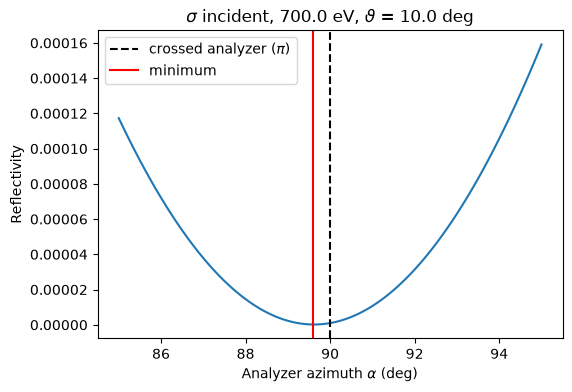

In [10]:
plt.figure(figsize=[6, 4])
plt.plot(analyzer, R[1, 0, :])
plt.axvline(90, color="k", ls="--", label=r"crossed analyzer ($\pi$)")
plt.axvline(analyzer[np.argmin(R[1, 0, :])], color="r", label="minimum")
plt.legend()
plt.xlabel(r"Analyzer azimuth $\alpha$ (deg)")
plt.ylabel("Reflectivity")
energy = res_analyzer.quantity("energy")[1]
theta = res_analyzer.quantity("theta")[1, 0]
plt.title(rf"$\sigma$ incident, {energy:~P}, $\vartheta$ = {theta:~P}")
plt.show()

The Kerr rotation of the magnetized Fe layer shifts the minimum of the reflectivity away from the crossed analyzer at 90°, and the Kerr ellipticity of the reflected light keeps it from reaching zero, see the Kerr angles below.

## High-Level Methods

The multilayer formalisms calculate the Jones matrices of the reflection and transmission in the linear $(\sigma, \pi)$ basis once, which is the expensive part.
They are calculated at once for the given and the reversed magnetization of the layers, e.g. for the magnetic asymmetry, where both are identical for a non-magnetic sample and for `Parratt`, which neglects the magnetization.
All other quantities follow from them.
Each quantity is calculated by a pair of methods, `homogeneous_<quantity>()` for a homogeneous structure and `inhomogeneous_<quantity>()` for strain, magnetization, and temperature maps:

| quantity | `<quantity>` | entries of the result (aliases) |
|---|---|---|
| Jones matrices | `jones_matrices` | `jones_reflection` (`jones_R`), `jones_transmission` (`jones_T`) |
| reflectivity and transmissivity | `reflectivity_transmissivity` | `reflectivity` (`R`), `transmissivity` (`T`) |
| rotation and ellipticity of the polarization, e.g. the Kerr and Faraday effect | `rotation_ellipticity` | `reflection_rotation` (`rot_R`), `reflection_ellipticity` (`ell_R`), `transmission_rotation` (`rot_T`), `transmission_ellipticity` (`ell_T`) |

All entries are also given for the reversed magnetization with the suffix `_phi`, e.g. `reflectivity_phi` (`R_phi`).
The aliases are short names of the same entries, e.g. `res.R` is `res.reflectivity`, which are used in the following examples, see the [overview of all results](#example_simulations_and_results).
Each method has a `calc_<kind>_<quantity>()` twin, e.g. {py:meth}`calc_homogeneous_reflectivity_transmissivity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_homogeneous_reflectivity_transmissivity>`, which returns the same entries as tuple of plain arrays, e.g. for fits.

The homogeneous methods take the optional `strains`, `magnetizations`, and `temps` with a value per sub-structure, while the inhomogeneous methods take the optional `strain_map`, `magnetization_map`, and `temp_map` of the [phonon](#example_strain_pulses), [magnetization](#example_LLG), and [heat](#example_excitation_NTM) simulations with a value per layer and delay.
The `temps` and `temp_map` are reserved for the temperature dependence of the dielectric tensor, e.g. on the electron temperature, which is planned for a future version, so that given temperatures raise an error yet.
All methods return a {py:class}`Result <udkm1Dsim.simulations.result.Result>` with the entries above and the coordinates `energy`, `qz`, and `theta` of the experiment, as well as the `delays` of an inhomogeneous result for given results of the upstream simulations, see the [simulations and results example](#example_simulations_and_results).
The inhomogeneous results are cached and can be calculated in parallel by `calc_type="parallel"` and a `dask_client`, on a local machine or a cluster.
The Jones matrices also give the reflectivity and transmissivity for any other polarization by {py:meth}`calc_reflectivity_transmissivity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_reflectivity_transmissivity>` and the rotation and ellipticity by {py:meth}`calc_rotation_ellipticity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_rotation_ellipticity>`.
The Jones vector of another polarization is given by {py:meth}`calc_incoming_polarization <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_incoming_polarization>` for its id, e.g. 1 for `"circ +"`, without changing the polarization of the simulation.
The optional `pol_in` and `pol_out` of `calc_reflectivity_transmissivity()` default to the polarizations set for the simulation, e.g. $\sigma$ without an analyzer as on its initialization.
In the same way, the lists of polarizations above follow from the Jones matrices of a single calculation, which makes them fast and easy to calculate.

:::{note}
The instrumental resolution, the electric fields and absorption profiles inside the layers, and the temperature dependence of the dielectric tensor are planned for future versions.
:::

Here, the longitudinal Kerr effect of the trilayer at the $L_3$ edge of Fe is calculated for incoming $\sigma$ polarization, and the reflectivity for circular polarization follows from the same Jones matrices.

In [11]:
sim.energy = np.r_[690:730:0.2] * u.eV
sim.theta = np.r_[10] * u.deg
sim.set_polarization("sigma", "none")

res_hom = sim.homogeneous_reflectivity_transmissivity()
res_kerr = sim.homogeneous_rotation_ellipticity()

# the same from the Jones matrices, which also give the circular reflectivity
res_jones = sim.homogeneous_jones_matrices()
jones_R, jones_R_phi = res_jones.jones_R, res_jones.jones_R_phi
jones_T, jones_T_phi = res_jones.jones_T, res_jones.jones_T_phi
kerr_rotation_jones, kerr_ellipticity_jones = sim.calc_rotation_ellipticity(jones_R)

circ_plus = sim.calc_incoming_polarization(1)
R_circ, _ = sim.calc_reflectivity_transmissivity(jones_R, jones_T, pol_in=circ_plus)
R_circ_phi, _ = sim.calc_reflectivity_transmissivity(jones_R_phi, jones_T_phi, pol_in=circ_plus)
unpolarized = sim.calc_incoming_polarization(0)
R_unpolarized, _ = sim.calc_reflectivity_transmissivity(jones_R, jones_T, pol_in=unpolarized)

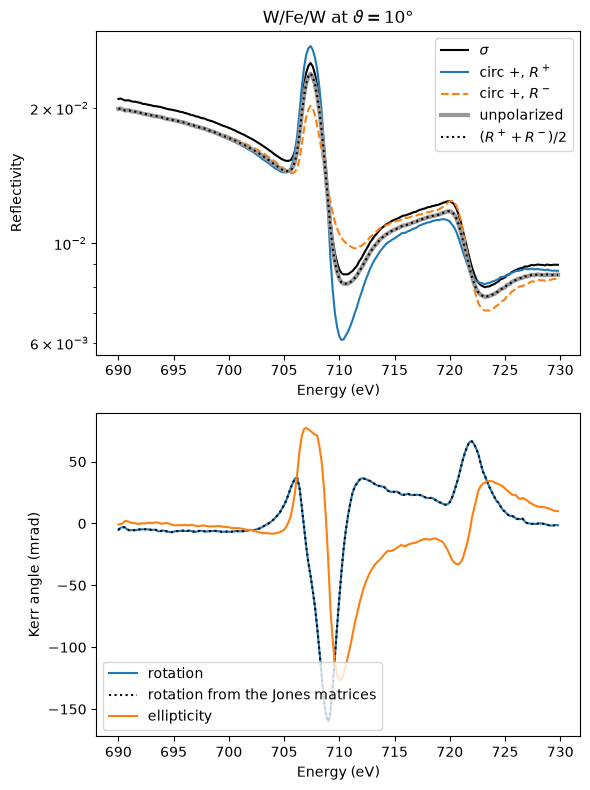

In [12]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.semilogy(res_hom.quantity("energy"), res_hom.R[:, 0], "k", label=r"$\sigma$")
plt.semilogy(res_hom.quantity("energy"), R_circ[:, 0], label=r"circ +, $R^+$")
plt.semilogy(res_hom.quantity("energy"), R_circ_phi[:, 0], "--", label=r"circ +, $R^-$")
plt.semilogy(
    res_hom.quantity("energy"), R_unpolarized[:, 0], color="0.6", lw=3, label="unpolarized"
)
plt.semilogy(
    res_hom.quantity("energy"),
    (R_circ[:, 0] + R_circ_phi[:, 0]) / 2,
    "k:",
    label=r"$(R^+ + R^-) / 2$",
)
plt.xlabel("Energy (eV)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title(r"W/Fe/W at $\vartheta = 10°$")

plt.subplot(2, 1, 2)
plt.plot(
    res_hom.quantity("energy"),
    res_kerr.quantity("rot_R", "mrad")[:, 0],
    label="rotation",
)
plt.plot(
    res_hom.quantity("energy"),
    kerr_rotation_jones[:, 0].to("mrad"),
    "k:",
    label="rotation from the Jones matrices",
)
plt.plot(
    res_hom.quantity("energy"),
    res_kerr.quantity("ell_R", "mrad")[:, 0],
    label="ellipticity",
)
plt.xlabel("Energy (eV)")
plt.ylabel("Kerr angle (mrad)")
plt.legend()

plt.tight_layout()
plt.show()

The circular dichroism of $R^+$ and $R^-$ for both directions of the magnetization is the resonant magnetic X-ray reflectivity at the $L_3$ edge of Fe, see the [example of resonant magnetic X-ray reflectivity](#example_resonant_magnetic_xray).
Their average is the reflectivity of unpolarized light, an incoherent mixture of $\sigma$ and $\pi$, as reversing a magnetization in the plane of incidence or along the surface normal is equivalent to switching the helicity.
This does not hold for a transverse magnetization along $x$, which changes the reflectivity of $\pi$ itself.

For the inhomogeneous methods, a `magnetization_map` with a demagnetization of the Fe layer by 50 % within 1 ps is defined here by hand, which is usually calculated by the [magnetization simulations](#example_LLG) or the [microscopic three-temperature model (M3TM)](#example_m3tm).
The magnetization is given in cartesian coordinates for every layer and delay.
As the strain is not changed, only the `magnetization_map` is given to {py:meth}`inhomogeneous_rotation_ellipticity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.inhomogeneous_rotation_ellipticity>`.

In [13]:
delays = np.r_[-1:5:0.05] * u.ps
L = S.get_number_of_layers()
amplitude = 1 - 0.5 * (1 - np.exp(-delays.to("ps").magnitude / 1)) * (delays.magnitude > 0)

magnetization_map = np.zeros([len(delays), L, 3])
magnetization_map[:, 1, 1] = amplitude  # the Fe layer along y

sim.energy = np.r_[707] * u.eV
sim.theta = np.r_[10] * u.deg
res_kerr_map = sim.inhomogeneous_rotation_ellipticity(magnetization_map=magnetization_map)
kerr_rotation = res_kerr_map.rot_R
kerr_ellipticity = res_kerr_map.ell_R

Progress:   0%|          | 0/120 [00:00<?, ?it/s]

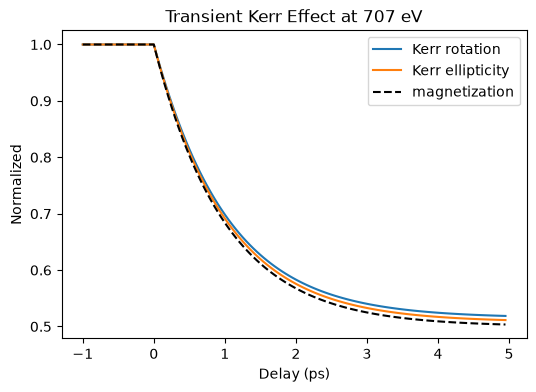

In [14]:
plt.figure(figsize=[6, 4])
plt.plot(delays, kerr_rotation[:, 0, 0] / kerr_rotation[0, 0, 0], label="Kerr rotation")
plt.plot(delays, kerr_ellipticity[:, 0, 0] / kerr_ellipticity[0, 0, 0], label="Kerr ellipticity")
plt.plot(delays, amplitude, "k--", label="magnetization")
plt.xlabel("Delay (ps)")
plt.ylabel("Normalized")
plt.legend()
plt.title("Transient Kerr Effect at 707 eV")
plt.show()

Both Kerr angles follow the magnetization of the Fe layer closely, as the gyrotropic part of its dielectric tensor scales linearly with the magnetization.
The small deviations stem from the Kerr angles, which are not strictly linear in the gyrotropic part at the strong resonance.

## Comparison of the Multilayer Formalisms

Far from the absorption edges, all multilayer formalisms give the same non-magnetic X-ray reflectivity, as shown in the [data fitting example](#example_data_fitting), where `Parratt` is used for the fit as the fastest one.
Close to an absorption edge, they differ in their treatment of the magnetization, which is compared here.

### Magnetic Asymmetry at the Fe $L_{3,2}$ Edges

As in Fig. 8 of {cite:t}`elzo2012`, the magnetic asymmetry $(R^+ - R^-)/(R^+ + R^-)$ is calculated as function of the photon energy at a grazing angle of 10° for the longitudinal and transverse geometry.
The reflectivities $R^\pm$ for the opposite magnetizations are returned by all formalisms at once.
The longitudinal magnetization along $y$ is probed by circularly polarized light, while the transverse magnetization along $x$ is probed by $\pi$ polarization.
`Parratt` is not included, as it neglects the magnetization.

In [15]:
energy = np.r_[690:740:0.1] * u.eV
geometries = {
    "longitudinal": {"magnetization": (0, 1, 0), "polarization": "circ +", "label": "circ +"},
    "transverse": {"magnetization": (1, 0, 0), "polarization": "pi", "label": r"$\pi$"},
}
asymmetry = {}
for geometry, settings in geometries.items():
    layer_Fe.magnetization = settings["magnetization"]
    for formalism in [ud.Elzo, ud.Stepanov, ud.BerremanElzo, ud.BerremanStepanov]:
        sim = formalism(S, True, save_data=False, disp_messages=False)
        sim.energy = energy
        sim.theta = np.r_[10] * u.deg
        sim.set_polarization(settings["polarization"], 0)
        res = sim.homogeneous_reflectivity_transmissivity()
        R, R_phi = res.R, res.R_phi
        asymmetry[geometry, formalism.__name__] = ((R - R_phi) / (R + R_phi))[:, 0]

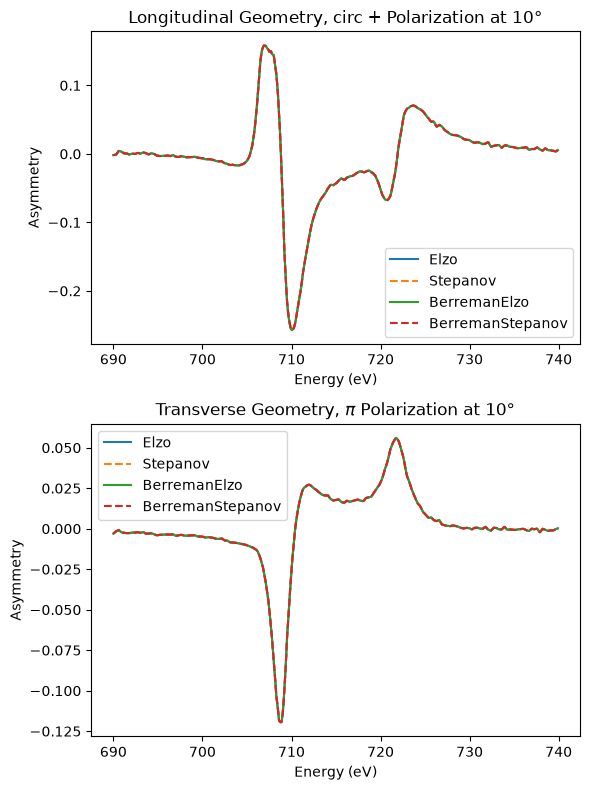

In [16]:
plt.figure(figsize=[6, 8])
styles = {"Elzo": "-", "Stepanov": "--", "BerremanElzo": "-", "BerremanStepanov": "--"}
for i, (geometry, settings) in enumerate(geometries.items()):
    plt.subplot(2, 1, i + 1)
    for name, style in styles.items():
        plt.plot(energy, asymmetry[geometry, name], style, label=name)
    plt.xlabel("Energy (eV)")
    plt.ylabel("Asymmetry")
    plt.legend()
    plt.title(f"{geometry.capitalize()} Geometry, {settings['label']} Polarization at 10°")

plt.tight_layout()
plt.show()

`Elzo` and `Stepanov` share the analytical eigenmodes and give identical results.
The exact eigenmodes of `BerremanElzo` and `BerremanStepanov` deviate only to second order in the gyrotropic part $\varepsilon^m$ of the dielectric tensor, which is largest at the $L_3$ resonance, but not visible on this scale.
Hence, a magnetic structure is typically fitted with the fast `Elzo` or `Stepanov` formalism and finally checked by `BerremanStepanov`.

The shape of the asymmetries follows Fig. 8 of {cite:t}`elzo2012`, while their magnitude depends on the tabulated magnetic form factors and the magnetic moment of the Fe layer, which were fitted in the paper.

### Stability

The up-going modes of the transfer matrices grow exponentially from the top towards the bottom of every layer with the imaginary part of their normal wave vector $k_z$, so that the elements of $M$ grow like $e^{\mathrm{Im}(k_z) D}$ for the total thickness $D$ of the stack.
The reflection, as their ratio, loses all numerical precision, once $e^{2\, \mathrm{Im}(k_z) D}$ approaches $10^{16}$, the inverse precision of double numbers.
Hence, the transfer matrices of `Elzo` become unstable for thick and strongly absorbing stacks, but also for evanescent waves with a large $\mathrm{Im}(k_z)$, e.g. at small grazing angles, i.e. small $q_z$, close to and below the critical angle of total reflection or for the coupling by a prism, while the scattering matrices of `Stepanov` stay stable.
This is shown for a [Fe(3 nm)/W(2 nm)]$_N$ multilayer at the $L_3$ edge of Fe, which absorbs strongly, with $N = 20$ and $N = 500$ periods, i.e. a total thickness of 100 nm and 2.5 µm.

In [17]:
layer_Fe.magnetization = (0, 1, 0)
period = ud.Structure("Fe/W")
period.add_sub_structure(layer_Fe, 1)
period.add_sub_structure(layer_W_bottom, 1)

repetitions = [20, 500]
theta = np.r_[5:60:0.01] * u.deg
R_stability = {}
for N in repetitions:
    S_ML = ud.Structure("multilayer")
    S_ML.add_sub_structure(period, N)
    S_ML.add_substrate(layer_Al2O3)
    for formalism in [ud.Elzo, ud.Stepanov]:
        sim = formalism(S_ML, True, save_data=False, disp_messages=False)
        sim.energy = np.r_[707] * u.eV
        sim.theta = theta
        sim.set_polarization("circ +", "none")
        with np.errstate(all="ignore"):
            res = sim.homogeneous_reflectivity_transmissivity()
            R_stability[N, formalism.__name__] = res.R[0, :]

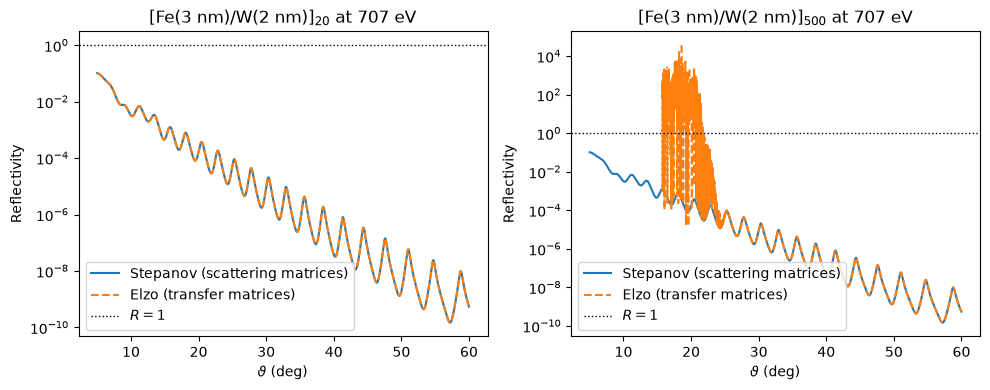

In [18]:
plt.figure(figsize=[10, 4])
for i, N in enumerate(repetitions):
    plt.subplot(1, 2, i + 1)
    plt.semilogy(theta, R_stability[N, "Stepanov"], label="Stepanov (scattering matrices)")
    plt.semilogy(theta, R_stability[N, "Elzo"], "--", label="Elzo (transfer matrices)")
    plt.axhline(1, color="k", ls=":", lw=1, label="$R = 1$")
    plt.xlabel(r"$\vartheta$ (deg)")
    plt.ylabel("Reflectivity")
    plt.legend(loc="lower left")
    plt.title(f"[Fe(3 nm)/W(2 nm)]$_{{{N}}}$ at 707 eV")

plt.tight_layout()
plt.show()

For 20 periods, the transfer and scattering matrices agree within the numerical precision.
For 500 periods, the reflectivity of the transfer matrices of `Elzo` exceeds 1 by orders of magnitude or even overflows below a grazing angle of about 26°, which is unphysical, while the scattering matrices of `Stepanov` converge to the reflectivity of the semi-infinite multilayer.
The breakdown starts at the smallest angles, as the path of the light through the absorbing stack grows with $1/\sin\vartheta$, and already for about 100 periods, i.e. a total thickness of 0.5 µm, at 5°.
Hence, the scattering-matrix formalisms should be used for thick, strongly absorbing, or highly repeated stacks, while the transfer matrices are faster for thin stacks.